In [59]:
import pandas as pd

In [60]:
df = pd.read_csv("train.csv")

In [62]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [63]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [64]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [67]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

In [68]:
num_cols = ["Age"]
num_pipe = make_pipeline(SimpleImputer(strategy="median")) 
df[num_cols] = num_pipe.fit_transform(df[num_cols]) 

In [69]:
cat_cols = ["Embarked"]
cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"))
df[cat_cols] = cat_pipe.fit_transform(df[cat_cols])

In [70]:
df.shape      

(891, 12)

In [71]:
df = df.drop("Cabin",axis=1) 

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns                                

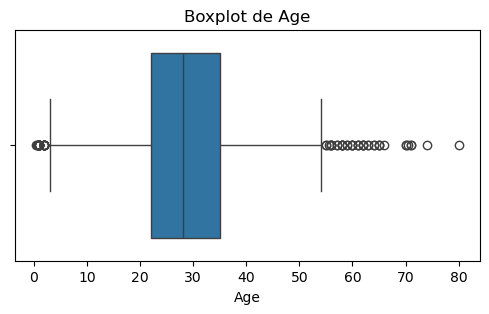

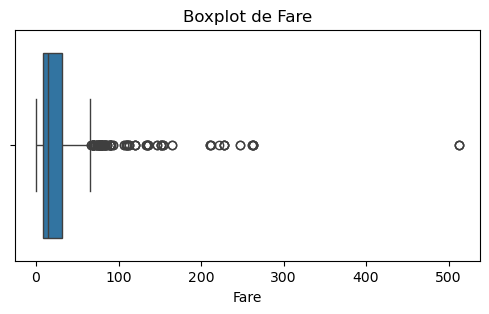

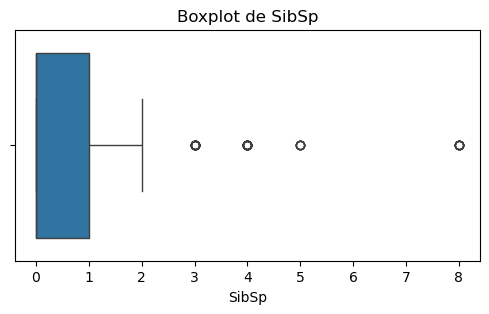

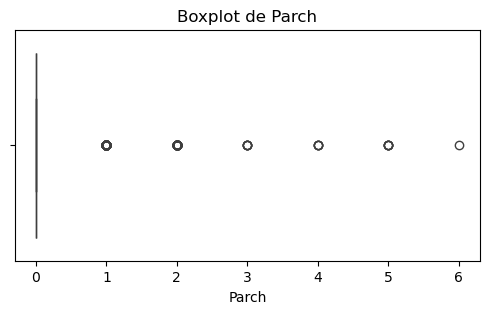

In [74]:
numeric_cols = ["Age", "Fare", "SibSp", "Parch"]
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.show()                                                                        

In [75]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
median = df["Age"].median()
df.loc[(df["Age"] < lower) | (df["Age"] > upper), "Age"] = median                    

In [76]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
median = df["Fare"].median()
df.loc[df["Fare"] > upper, "Fare"] = median                                 

In [79]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object

In [81]:
from sklearn.preprocessing import OneHotEncoder

cat_cols_coder = ["Sex", "Embarked"]
cat_pipe_coder = make_pipeline(OneHotEncoder(handle_unknown="ignore"))

cat_encoded = cat_pipe_coder.fit_transform(df[cat_cols_coder])   

In [85]:
from sklearn.preprocessing import MinMaxScaler  
num_pipe_s = make_pipeline(MinMaxScaler())

df_norm = df.copy()             
df_norm[numeric_cols] = num_pipe_s.fit_transform(df_norm[numeric_cols])

In [86]:
from sklearn.preprocessing import StandardScaler   

num_pipe_std = make_pipeline(StandardScaler())
df_std = df.copy()     
df_std[numeric_cols] = num_pipe_std.fit_transform(df_std[numeric_cols])

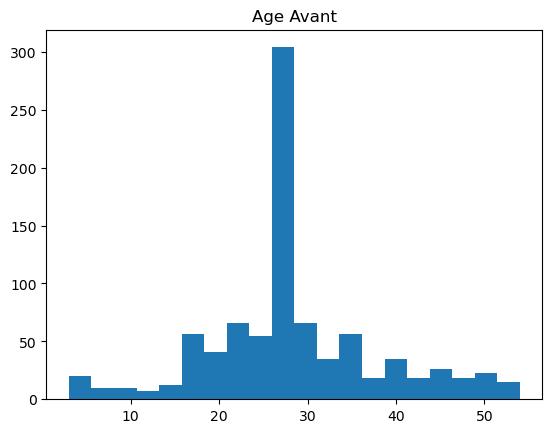

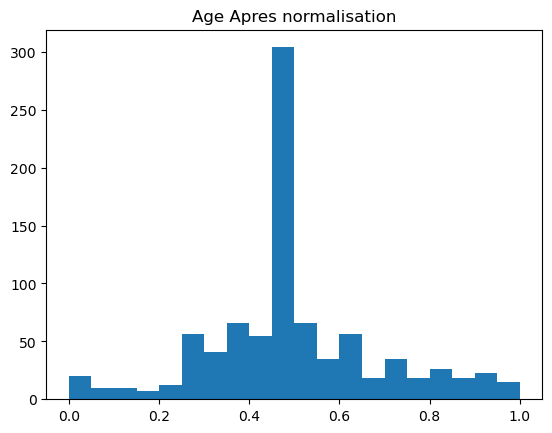

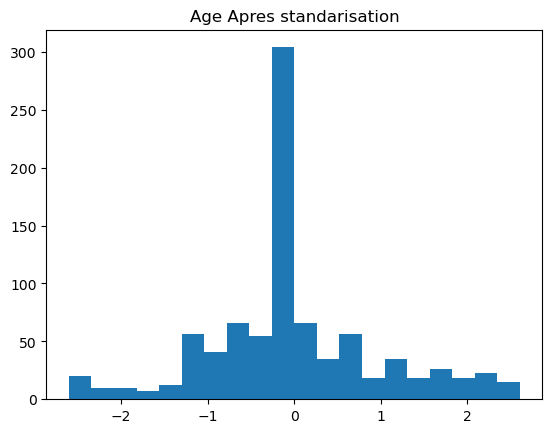

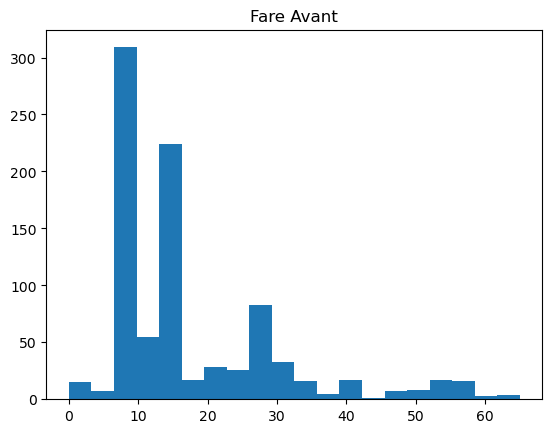

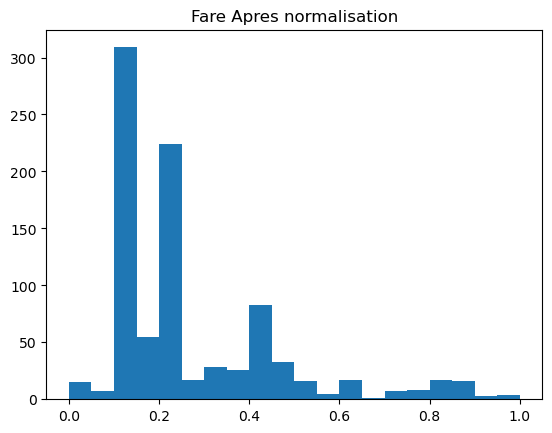

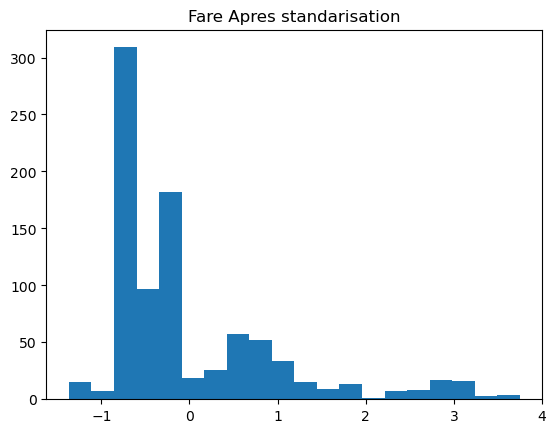

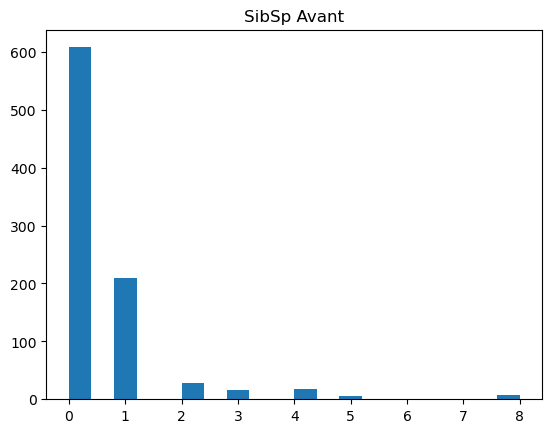

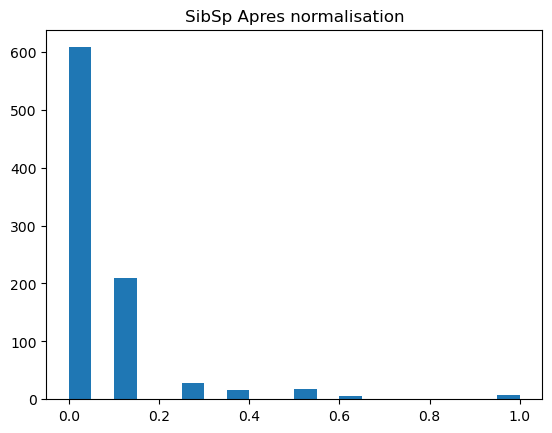

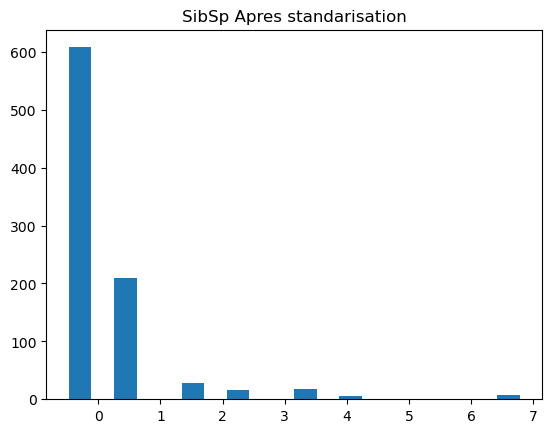

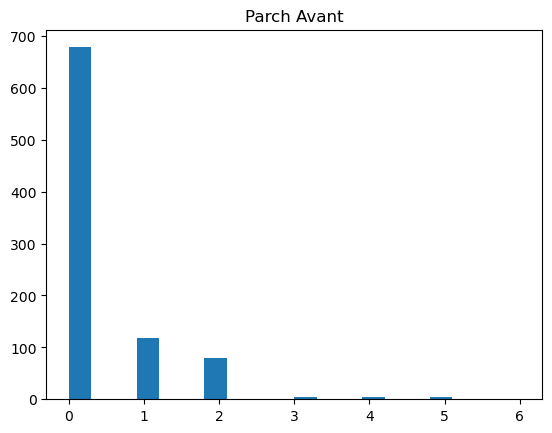

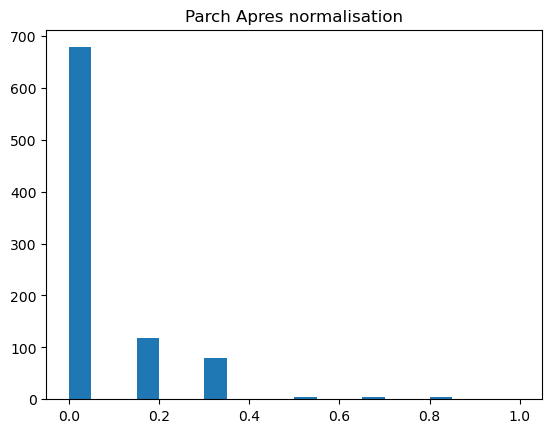

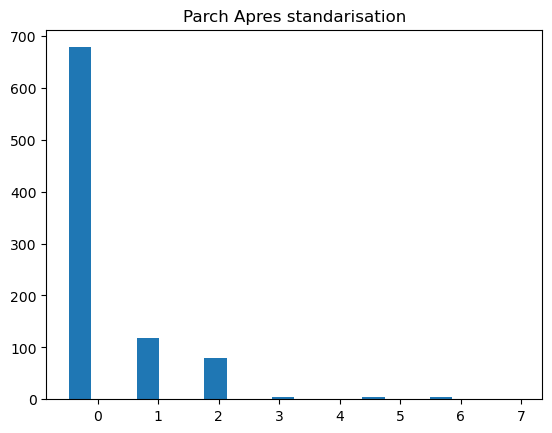

In [87]:
import matplotlib.pyplot as plt

for col in numeric_cols:
    plt.hist(df[col], bins=20)
    plt.title(col + " Avant")
    plt.show()
    plt.hist(df_norm[col], bins=20)
    plt.title(col + " Apres normalisation")
    plt.show()
    plt.hist(df_std[col], bins=20)
    plt.title(col + " Apres standarisation")
    plt.show()

In [89]:
df["Survived"].value_counts() 

Survived
0    549
1    342
Name: count, dtype: int64